
Testare pentru loss: log_loss 
Scoruri CV (accuratețe): [0.89010989 0.89010989 0.91208791 0.85714286 0.84615385]
Media scorurilor: 0.8791
Acuratețe pe test: 0.9123

Predicție pentru raza=18, textura=10: Malign
Probabilitate de malignitate: 0.5807


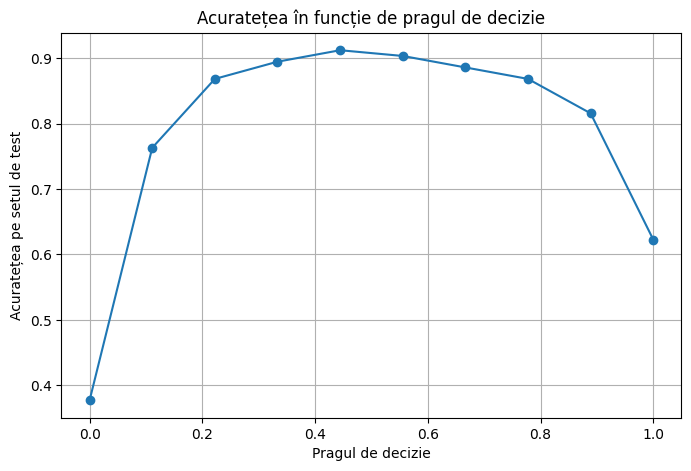


Testare pentru loss: modified_huber 
Scoruri CV (accuratețe): [0.87912088 0.87912088 0.93406593 0.87912088 0.84615385]
Media scorurilor: 0.8835
Acuratețe pe test: 0.9211

Predicție pentru raza=18, textura=10: Malign
Probabilitate de malignitate: 0.5895


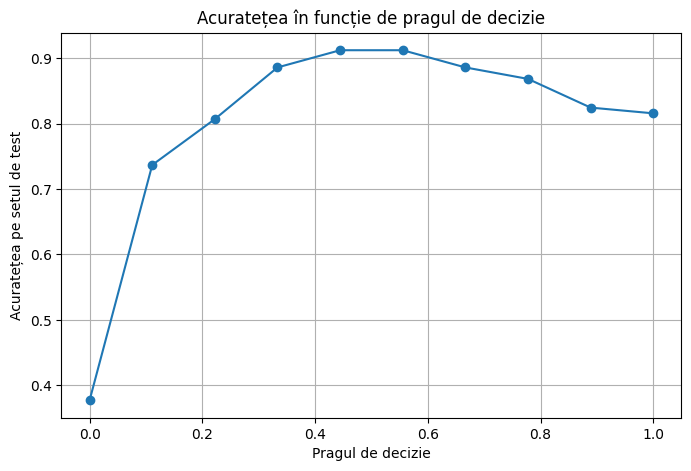

In [3]:
from matplotlib import pyplot as plt
from ucimlrepo import fetch_ucirepo
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import mean_squared_error, accuracy_score

breast_cancer = fetch_ucirepo(id=17)
X = breast_cancer.data.features[["radius1", "texture1"]].values
y = breast_cancer.data.targets["Diagnosis"].map({"M": 1, "B": 0}).values


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#investigarea diferitelor funcții de loss
loss_list = ["log_loss", "modified_huber"]
epochs = 300
batch_size = 16
classes = np.array([0, 1])
n_samples = X_train.shape[0]


for loss in loss_list:
    print(f"\nTestare pentru loss: {loss} ")

    model = SGDClassifier(
        loss=loss,
        learning_rate='constant',
        eta0=0.01,
        max_iter=1,
        tol=None,
        random_state=42
    )

    # folosirea validarii încrucișate
    cv = StratifiedKFold(n_splits=5)
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    print(f"Scoruri CV (accuratețe): {cv_scores}")
    print(f"Media scorurilor: {np.mean(cv_scores):.4f}")

    for epoch in range(epochs):
        indices = np.random.choice(n_samples, batch_size, replace=False)
        X_batch = X_train[indices]
        y_batch = y_train[indices]
        model.partial_fit(X_batch, y_batch, classes=classes)

    # ce se întâmplă dacă se modifică pragul de decizie
    y_probs = model.predict_proba(X_test)[:, 1]
    thresholds = np.linspace(0.0, 1.0, 10)
    accuracies = [accuracy_score(y_test, (y_probs >= t).astype(int)) for t in thresholds]

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Acuratețe pe test: {accuracy:.4f}")

    sample = np.array([[18, 10]])
    sample_scaled = scaler.transform(sample)
    pred = model.predict(sample_scaled)[0]
    label = "Malign" if pred == 1 else "Benign"
    print(f"\nPredicție pentru raza=18, textura=10: {label}")

    prob = model.predict_proba(sample_scaled)[0][1]
    print(f"Probabilitate de malignitate: {prob:.4f}")

    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, accuracies, marker='o')
    plt.title("Acuratețea în funcție de pragul de decizie")
    plt.xlabel("Pragul de decizie")
    plt.ylabel("Acuratețea pe setul de test")
    plt.grid(True)
    plt.show()



In [4]:
from MyMiniBatchLogisticRegression import MyMiniBatchLogisticRegression

breast_cancer = fetch_ucirepo(id=17)
X_all = breast_cancer.data.features
y_all = breast_cancer.data.targets


X = X_all[["radius1", "texture1"]].values
y = y_all["Diagnosis"].map({"M": 1, "B": 0}).values


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


model = MyMiniBatchLogisticRegression(learning_rate=0.1, epochs=1000, batch_size=16)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Acuratețe pe test: {accuracy:.4f}")


input_normalizat = scaler.transform([[18, 10]])
prob = model.predict_proba(input_normalizat)[0]
label = "Malign" if prob >= 0.5 else "Benign"
print(f"\nPredicție pentru raza=18, textura=10: {label}")
print(f"Probabilitate de malignitate: {prob:.4f}")




Acuratețe pe test: 0.9123

Predicție pentru raza=18, textura=10: Malign
Probabilitate de malignitate: 0.7463
